# 10 · Time validation, model comparisons, and error analysis

## Research extension
Compare several prediction strategies using identical time blocks, duplicate protection and vehicle inputs. Quantify the value of feature groups and find where errors concentrate. This complements [the four research questions](../docs/proposal.md) and [notebook 05](05_adjusted_associations_and_prediction.ipynb).

## Experiment design

- Target: listed USD asking prices within $500–$150,000, with a usable local posting date. The metrics apply to this in-band cohort.
- Fit on earlier dates and validate on three consecutive six-day April blocks. Repeated-vehicle exclusion removes earlier exact VIN or attribute fingerprint matches to a validation block. These keys are used for splitting only. Exact attributes can coincidentally match unrelated vehicles, so compare VIN-only with the combined rule.
- Score the already viewed **May 1–4** block as a historical comparison. Choose the best specification by pooled April MAE. The May block remains a previously examined benchmark.
- Compare global median, a grouped median that backs off from make/type/five-year age bands at 40 listings, log-price ridge, histogram gradient boosting, and CatBoost. The learned models receive the same age, mileage and recorded category fields. Preprocessors are fit only on the corresponding training block. Model settings are fixed in the source.
- MAE is the mean absolute USD error. Median signed error is predicted minus observed, so positive values indicate overprediction. Lower MAE is better.

In [1]:
from pathlib import Path
import json
import sys

root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src" / "research_data.py").is_file()), None)
if root is None:
    raise RuntimeError("Start Jupyter from the repository or notebooks directory.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from src.research_data import load_research_data
from src.research_models import model_cohort, run_experiment
from src.research_figures import (
    error_profile, feature_ablation, figure_style, save_figure,
    segment_errors, validation_by_window,
)
from src.research_models import MODELS, score

figure_style()
directory = root / "outputs" / "validation"
directory.mkdir(parents=True, exist_ok=True)
cohort = model_cohort(load_research_data(root))
metrics, samples, predictions, diagnostics = run_experiment(root, cohort, "benchmark")
display(samples.set_index("window"))


,earlier_n,train_n,test_n,vin_removed,combined_removed
window,,,,,
Apr 13–18,59963,46757,51432,10935,13206
Apr 19–24,111395,87690,74265,19612,23705
Apr 25–30,185660,149482,100620,28859,36178
May 1–4,286280,244651,98248,33976,41629


## 1 · Compare specifications across time

The chart shows each model's MAE per block. The April summary pools the individual absolute errors across the three disjoint validation windows, so larger blocks have more weight. The May column is for historical comparison.

Selected by pooled April MAE: Gradient boosting


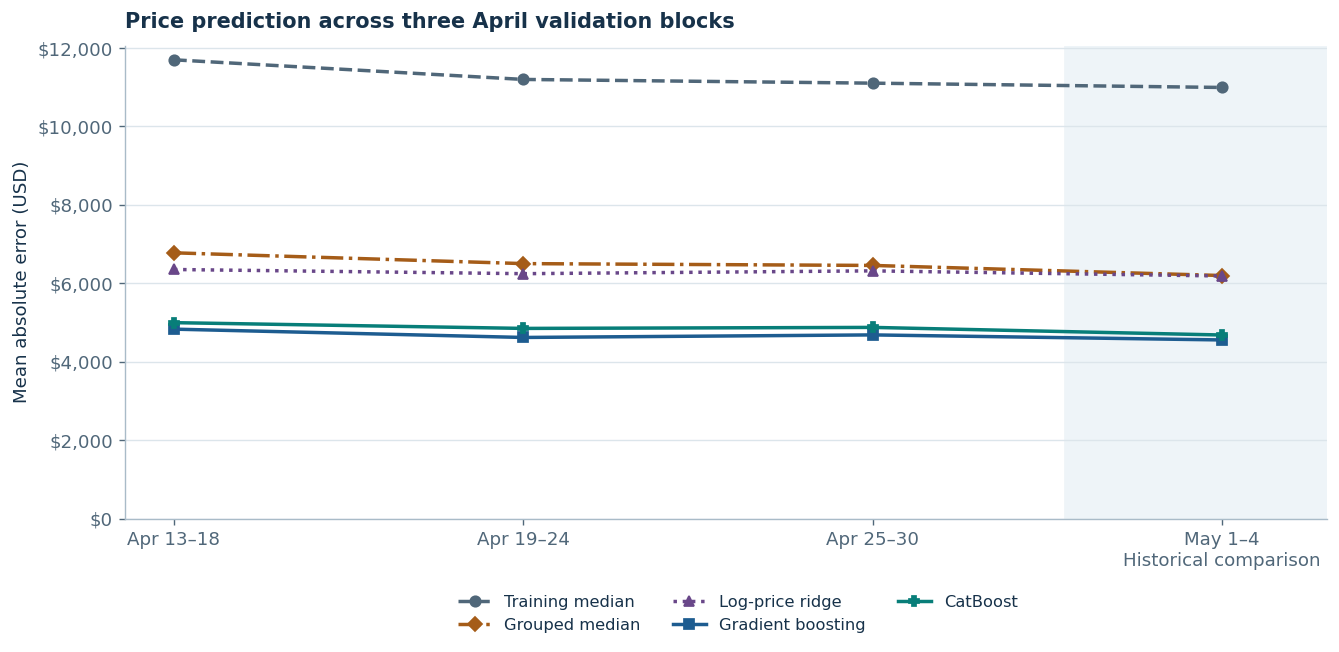

,mae,rmse,r2,median_error,may_mae
Gradient boosting,4697.0,8287.0,0.686,-342.0,4556.0
CatBoost,4895.0,8468.0,0.672,-422.0,4682.0
Log-price ridge,6302.0,10071.0,0.536,-415.0,6186.0
Grouped median,6544.0,10448.0,0.500,-5.0,6198.0
Training median,11269.0,15106.0,-0.044,266.0,10993.0


In [2]:
fig = validation_by_window(metrics)
save_figure(fig, directory, "rolling_validation_mae")
plt.show()
april = predictions.loc[predictions["window"].ne("May 1–4")]
may = predictions.loc[predictions["window"].eq("May 1–4")]
ranking = pd.DataFrame({
    name: score(april["price"], april[name]) for name in MODELS
}).T.sort_values("mae")
ranking["may_mae"] = [score(may["price"], may[name])["mae"] for name in ranking.index]
display(ranking.round({"mae": 0, "rmse": 0, "r2": 3, "median_error": 0, "may_mae": 0}))
selected = ranking.index[0]
print(f"Selected by pooled April MAE: {selected}")


## 2 · Locate systematic errors

Group the pooled April predictions by observed asking price and age. The lower panels show signed bias, while the top panels report typical error size using MAE. Conditioning on the observed outcome makes these plots diagnostic rather than prospective segmentation. State summaries below require 500 predictions and reflect the observed mix of listings.

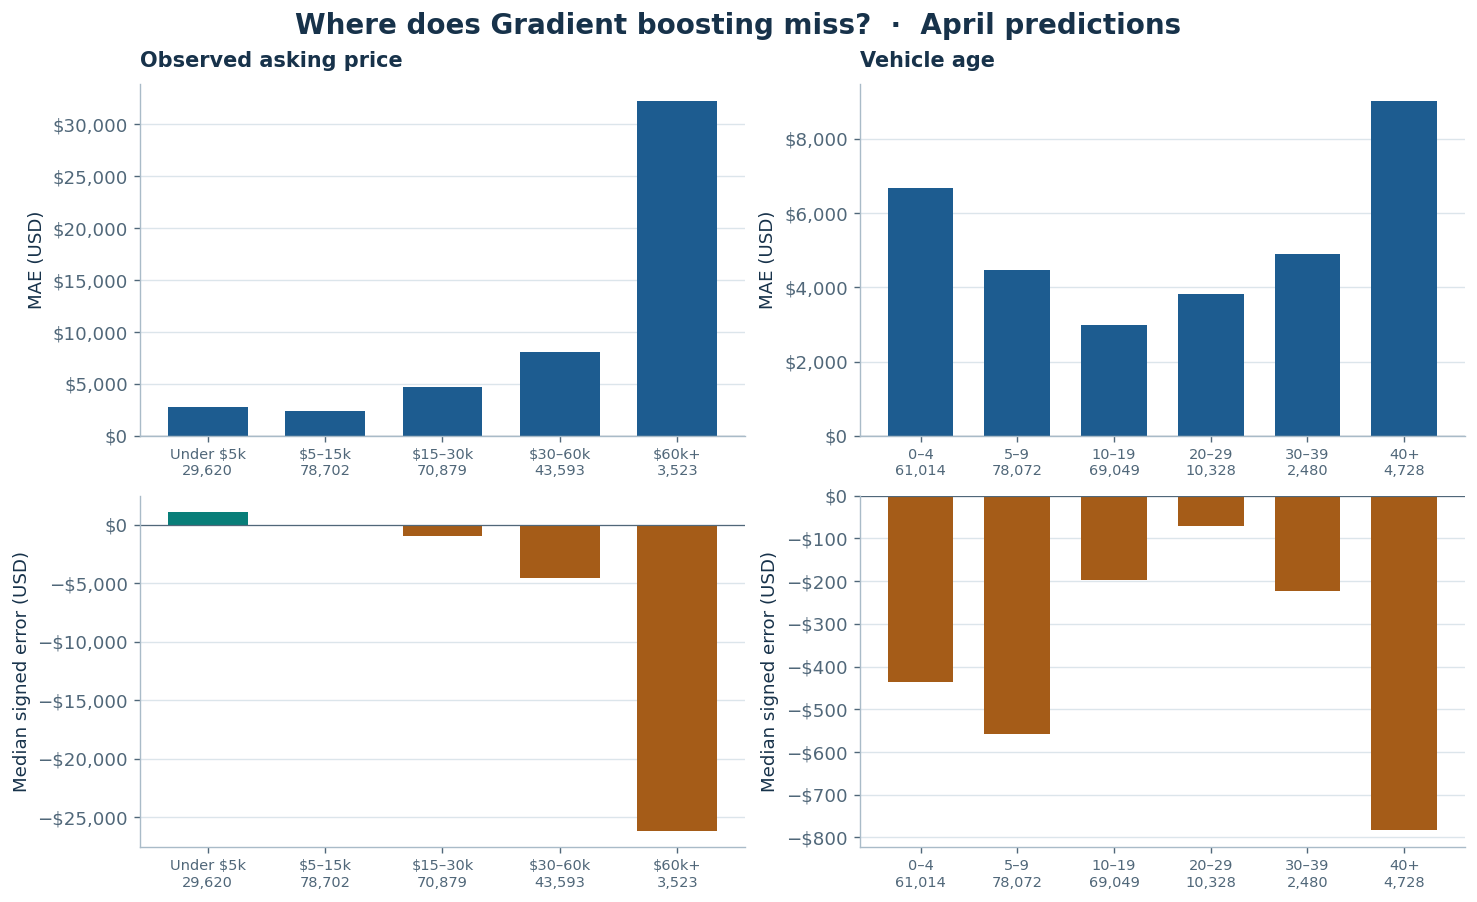

,n,mae,median_error
state,,,
or,7640,8065.0,-2089.0
ut,710,6527.0,143.0
nv,1802,6264.0,-783.0
wv,585,6214.0,278.0
wa,5897,5857.0,-1139.0
hi,1345,5837.0,-1338.0
nm,2507,5714.0,-590.0
ok,3972,5555.0,-265.0


In [3]:
price = segment_errors(predictions, selected, "price",
                       [500, 5_000, 15_000, 30_000, 60_000, np.inf],
                       ["Under $5k", "$5–15k", "$15–30k", "$30–60k", "$60k+"])
age = segment_errors(predictions, selected, "vehicle_age",
                     [0, 5, 10, 20, 30, 40, np.inf],
                     ["0–4", "5–9", "10–19", "20–29", "30–39", "40+"])
fig = error_profile(price, age, selected)
save_figure(fig, directory, "price_and_age_error_profile")
plt.show()
signed = april[selected] - april["price"]
state_error = april.assign(signed=signed, absolute=signed.abs()).groupby("state").agg(
    n=("signed", "size"), mae=("absolute", "mean"), median_error=("signed", "median")
)
state_error = state_error.loc[state_error["n"].ge(500) & state_error.index.to_series().ne("__missing__")]
display(state_error.sort_values("mae", ascending=False).head(8).round(0))


## 3 · Remove groups of features and vary duplicate protection

Use the Apr 25–30 block and the same gradient-boosting settings for the ablation experiment. A feature group's removal changes how other predictors are used, so these comparisons measure incremental predictive value in this experiment. The last row of the table changes only the duplicate exclusion rule. With VIN-only exclusion, more related listings may occur on opposite sides of the split.

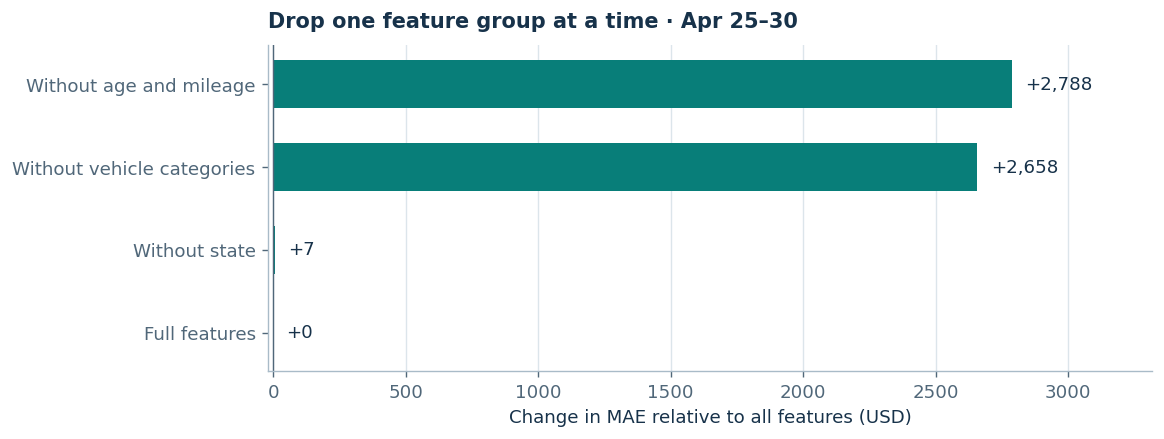

,mae,rmse,r2,median_error
specification,,,,
Full features,4685.0,8570.0,0.665,-304.0
Without age and mileage,7472.0,11754.0,0.370,-292.0
Without vehicle categories,7343.0,11675.0,0.378,-143.0
Without state,4692.0,8486.0,0.671,-376.0
"Full features, VIN-only exclusion",4685.0,8563.0,0.665,-322.0


In [4]:
fig = feature_ablation(diagnostics)
save_figure(fig, directory, "feature_ablation")
plt.show()
display(diagnostics.set_index("specification").round({"mae": 0, "rmse": 0, "r2": 3, "median_error": 0}))
metrics.to_csv(directory / "model_scores_by_window.csv", index=False)
samples.to_csv(directory / "split_sizes.csv", index=False)
ranking.to_csv(directory / "pooled_april_scores.csv")
diagnostics.to_csv(directory / "april_feature_ablation.csv", index=False)
price.to_csv(directory / "price_band_errors.csv")
age.to_csv(directory / "age_band_errors.csv")
state_error.to_csv(directory / "state_errors.csv")


## Takeaways

In [5]:
base = ranking.loc["Grouped median", "mae"]
chosen = ranking.loc[selected]
gain = 100 * (1 - chosen.mae/base)
comparison = diagnostics.set_index("specification")
strict_mae = comparison.loc["Full features", "mae"]
vin_mae = comparison.loc["Full features, VIN-only exclusion", "mae"]
display(Markdown(
    f"- **{selected}** had the lowest pooled April MAE at **${chosen.mae:,.0f}**, "
    f"**{gain:.1f}%** below the grouped median. April used **{len(april):,}** validation listings.\n"
    f"- On the already viewed May block the same specification's MAE was **${chosen.may_mae:,.0f}**.\n"
    f"- Apr 25–30 gradient boosting scored **${strict_mae:,.0f}** with combined exclusion and "
    f"**${vin_mae:,.0f}** with VIN-only exclusion. See split sizes and error profiles above."
))
aggregate = {"selected_model": selected, "april_n": len(april), "may_n": len(may),
             "april_mae": float(chosen.mae), "may_mae": float(chosen.may_mae),
             "gain_vs_grouped_median_pct": float(gain), "combined_april_last_mae": float(strict_mae),
             "vin_only_april_last_mae": float(vin_mae)}
(directory / "summary.json").write_text(json.dumps(aggregate, indent=2), encoding="utf-8")


- **Gradient boosting** had the lowest pooled April MAE at **$4,697**, **28.2%** below the grouped median. April used **226,317** validation listings.
- On the already viewed May block the same specification's MAE was **$4,556**.
- Apr 25–30 gradient boosting scored **$4,685** with combined exclusion and **$4,685** with VIN-only exclusion. See split sizes and error profiles above.